In [1]:
from __future__ import annotations
from minigrid.core.constants import COLOR_NAMES
from minigrid.core.grid import Grid
from minigrid.core.mission import MissionSpace
from minigrid.core.world_object import Door, Goal, Key, Wall
from minigrid.manual_control import ManualControl
from minigrid.minigrid_env import MiniGridEnv
import gymnasium as gym
import minigrid
import networkx as nx
from functions import *
from matplotlib.gridspec import GridSpec

In [2]:
import gymnasium
from minigrid.envs.wfc.config import WFC_PRESETS_INCONSISTENT, register_wfc_presets
from minigrid.envs.wfc.config import WFC_PRESETS_SLOW, register_wfc_presets

register_wfc_presets(WFC_PRESETS_SLOW, gymnasium.register)
register_wfc_presets(WFC_PRESETS_INCONSISTENT, gymnasium.register)

In [6]:
# Create the WFC Maze Simple environment
env = gym.make("MiniGrid-WFC-MazeSimple-v0",size=20)#,render_mode='human')
obs, info = env.reset()
#env.render()

In [7]:
graph = minigrid_maze_to_graph(env)

A, index = graph_to_adjacency_matrix(graph, directed=False)

G = nx.DiGraph()
for state, neighbors in graph.items():
    G.add_node(state)
    for action, nxt in neighbors.items():
        G.add_edge(state, nxt, action=action)

index_state = {state: i for i, state in enumerate(sorted(graph.keys()))}

base_env = env.unwrapped if hasattr(env, "unwrapped") else env
start = tuple(base_env.agent_pos) if hasattr(base_env, "agent_pos") else None
goal = get_goal_state(base_env)

geomem_dict = graph_to_geomem_dict(
    graph
)

eff_res = effective_resistance_adj(A)

print("Transition sample:\n", list(geomem_dict["transition"].items())[:5])
print("Valid action count:\n", len(geomem_dict["valid"]))
print(f'Raw Commutativity Measure: {effective_commutativity(DictEnvAdapter(geomem_dict)):.2f}')
print(f'Valid Commutativity Measure: {effective_commutativity(DictEnvAdapter(geomem_dict),valid_only=True):.2f}')
print(f'Effective Resistance Measure (Laplacian): {np.nanmean(link_curvature(DictEnvAdapter(geomem_dict),eff_res)):.2f}')

Transition sample:
 [(((1, 2), 'L'), (1, 2)), (((1, 2), 'R'), (1, 3)), (((1, 2), 'U'), (1, 2)), (((1, 2), 'D'), (2, 2)), (((1, 3), 'L'), (1, 2))]
Valid action count:
 284
Raw Commutativity Measure: 0.54
Valid Commutativity Measure: 1.00
Effective Resistance Measure (Laplacian): -0.42


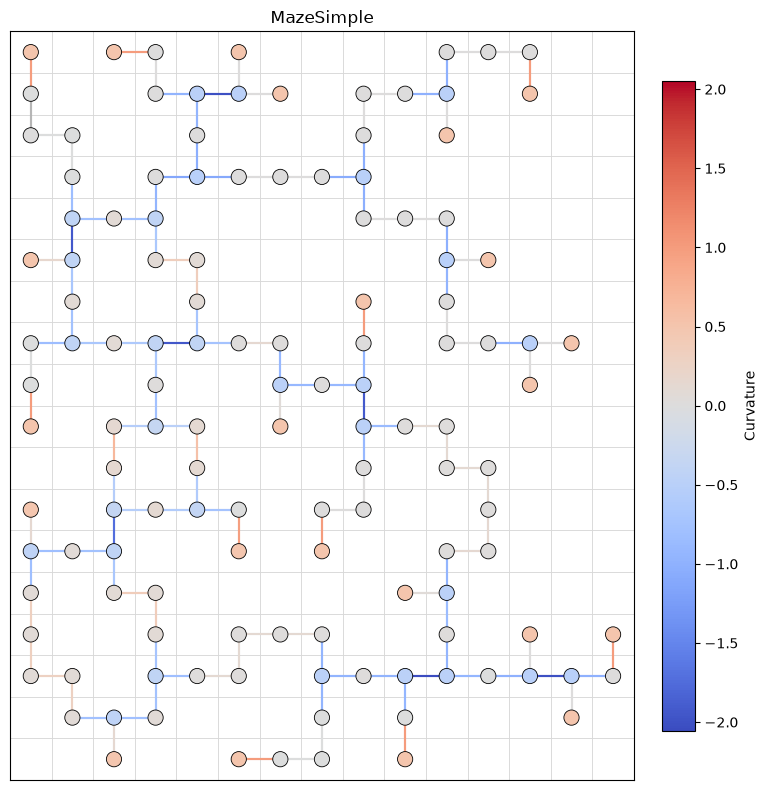

(0.5451541850220264, 1.0, np.float64(-0.3609802003207629))

In [10]:
setup_env("MiniGrid-WFC-MazeSimple-v0",edge_length=20,visualise=True)

# Running the Measure through all possibilities



In [6]:
env_list = [
    "MiniGrid-WFC-MazeSimple-v0",
    "MiniGrid-WFC-DungeonMazeScaled-v0",
    "MiniGrid-WFC-RoomsFabric-v0",
    "MiniGrid-WFC-ObstaclesBlackdots-v0",
    "MiniGrid-WFC-ObstaclesAngular-v0",
    #"MiniGrid-WFC-ObstaclesHogs3-v0",
    #"MiniGrid-WFC-MazeKnot-v0",
    "MiniGrid-WFC-MazeWall-v0",
    #"MiniGrid-WFC-RoomsOffice-v0",
    "MiniGrid-WFC-ObstaclesHogs2-v0",
    #"MiniGrid-WFC-Skew2-v0",
    "MiniGrid-WFC-Maze-v0",
    #"MiniGrid-WFC-MazeSpirals-v0",
    #"MiniGrid-WFC-MazePaths-v0",
    "MiniGrid-WFC-Mazelike-v0",
    #"MiniGrid-WFC-Dungeon-v0",
    #"MiniGrid-WFC-DungeonRooms-v0",
    #"MiniGrid-WFC-DungeonLessRooms-v0",
    #"MiniGrid-WFC-DungeonSpirals-v0",
    "MiniGrid-WFC-RoomsMagicOffice-v0",
    #"MiniGrid-WFC-SkewCave-v0",
    #"MiniGrid-WFC-SkewLake-v0"
]

In [ ]:
%%time
# 2D colormap of the three measures (axis 1 is maze type, axis 2 is size)
sizes = [10,20,50]
runs = 5
raw_results = np.zeros([len(env_list),len(sizes),runs])
#valid_results = np.zeros(raw_results.shape)
resistance_results = np.zeros(raw_results.shape)

for env_idx, env_string in enumerate(env_list):
    for size_idx, size in enumerate(sizes):
        for i in range(runs):
            raw,_,res = setup_env(env_string,size)
            raw_results[env_idx,size_idx,i] = raw
            #valid_results[env_idx,size_idx,i] = valid
            resistance_results[env_idx,size_idx,i] = res

CPU times: user 9min 57s, sys: 34 ms, total: 9min 57s
Wall time: 2min 30s


In [12]:
env_names = [env_string.split('-')[2] for env_string in env_list]

<timed exec>:47: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
<timed exec>:47: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.


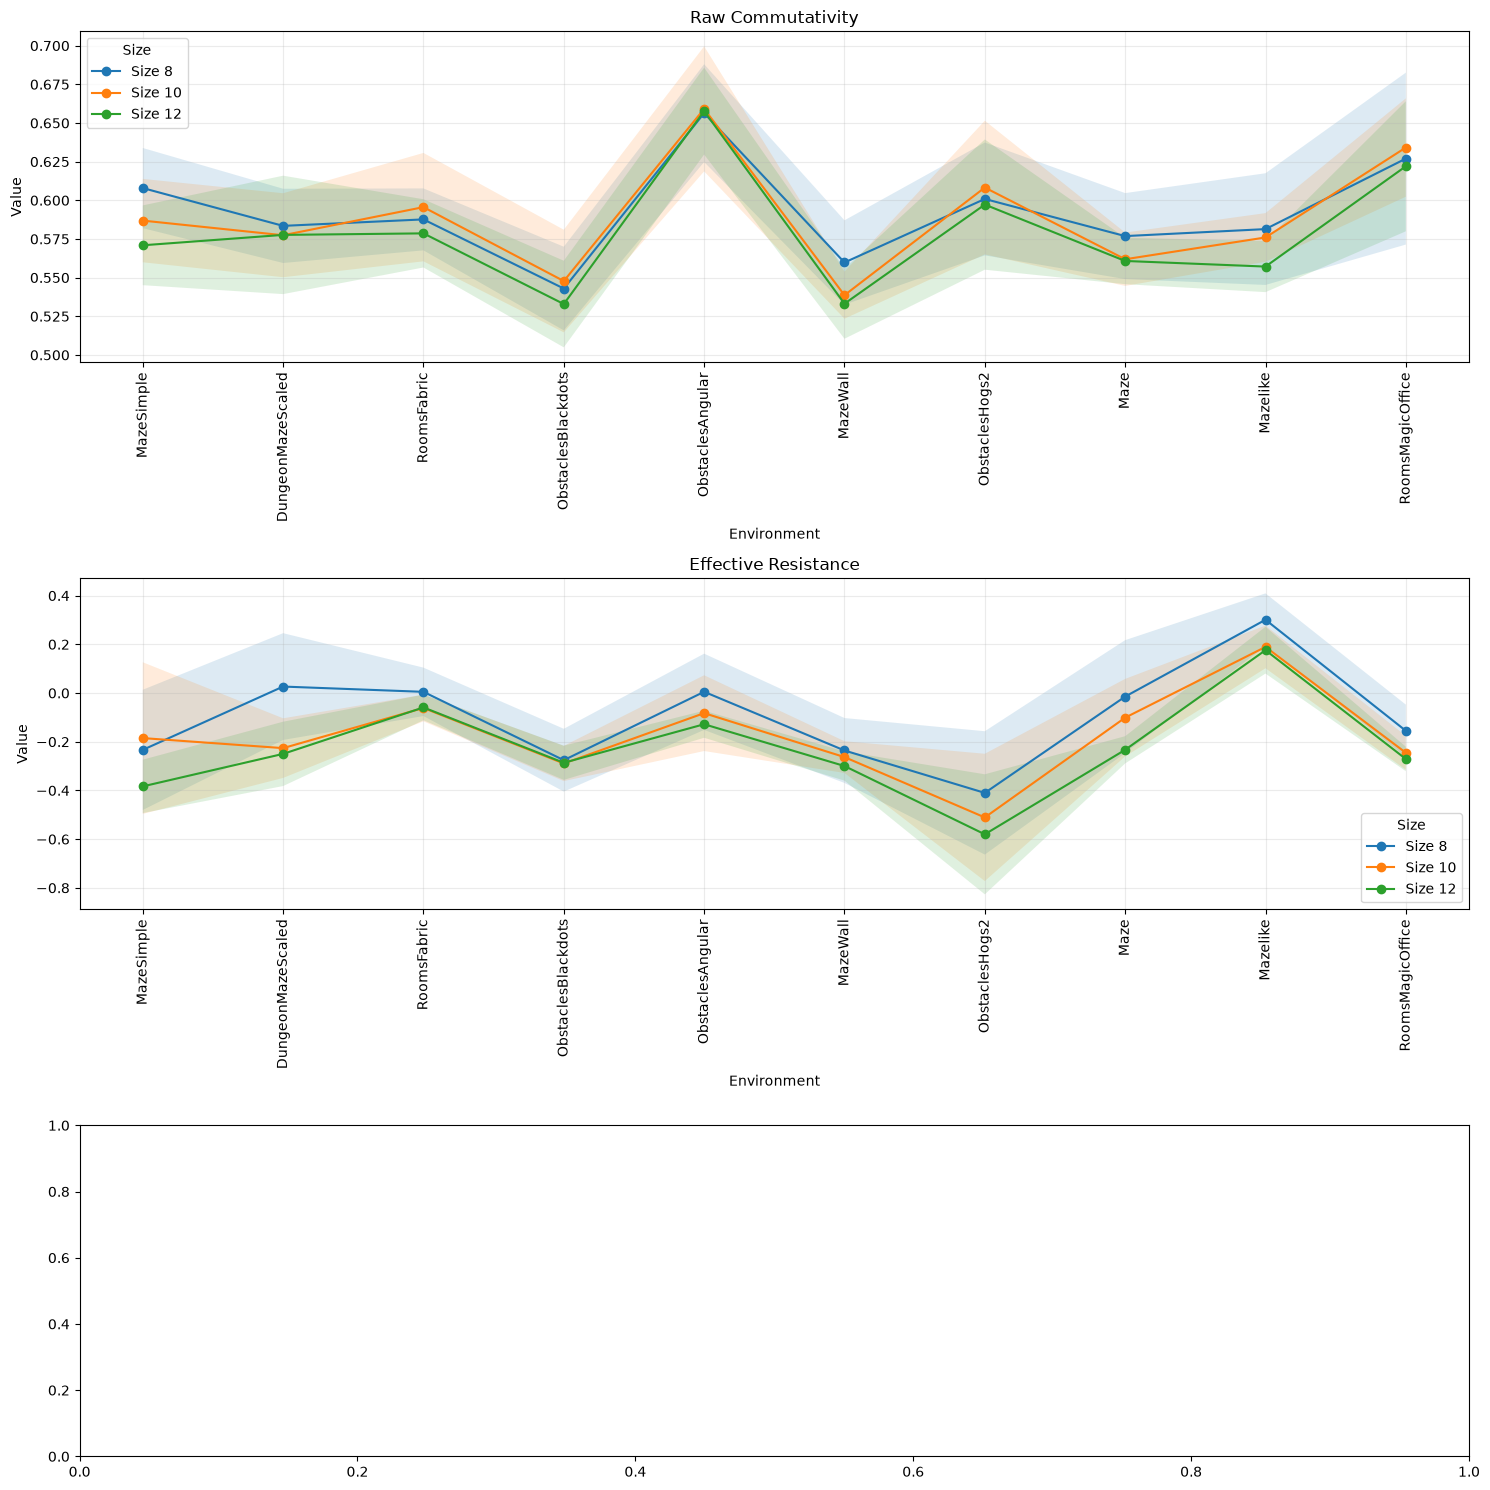

CPU times: user 234 ms, sys: 12 ms, total: 246 ms
Wall time: 245 ms


In [9]:
%%time
import numpy as np
import matplotlib.pyplot as plt

# shapes:
# raw_results.shape == (n_envs, n_sizes, n_runs)
# valid_results.shape == (n_envs, n_sizes, n_runs)
# resistance_results.shape == (n_envs, n_sizes, n_runs)

env_names = [env_string.split('-')[2] for env_string in env_list]

# compute mean and variance across runs
raw_mean = np.nanmean(raw_results, axis=2)      # (n_envs, n_sizes)
raw_var  = np.nanvar(raw_results, axis=2)        # (n_envs, n_sizes)

#valid_mean = np.nanmean(valid_results, axis=2)
#valid_var  = np.nanvar(valid_results, axis=2)

res_mean = np.nanmean(resistance_results, axis=2)
res_var  = np.nanvar(resistance_results, axis=2)

# for plotting:
# x = environment names
# each size is one line
# rows = measure, columns = maybe not needed
# just 3 separate subplots

fig, axes = plt.subplots(3, 1, figsize=(15, 15), sharey=False)

measure_sets = [
    ("Raw Commutativity", raw_mean, raw_var),
    #("Valid Commutativity", valid_mean, valid_var),
    ("Effective Resistance", res_mean, res_var),
]

for ax, (title, mean_data, var_data) in zip(axes, measure_sets):
    # mean_data shape: (n_envs, n_sizes)
    # transpose to (n_sizes, n_envs) so each row is a size
    mean_plot = mean_data.T
    var_plot = var_data.T

    for i, size in enumerate(sizes):
        y = mean_plot[i, :]
        sigma = np.sqrt(var_plot[i, :])
        ax.plot(env_names, y, marker="o", label=f"Size {size}")
        ax.fill_between(env_names, y - sigma, y + sigma, alpha=0.15)

    ax.set_xticklabels(env_names, rotation=90)
    ax.set_title(title)
    ax.set_xlabel("Environment")
    ax.set_ylabel("Value")
    ax.grid(alpha=0.25)
    ax.legend(title="Size")

plt.tight_layout()
plt.show()

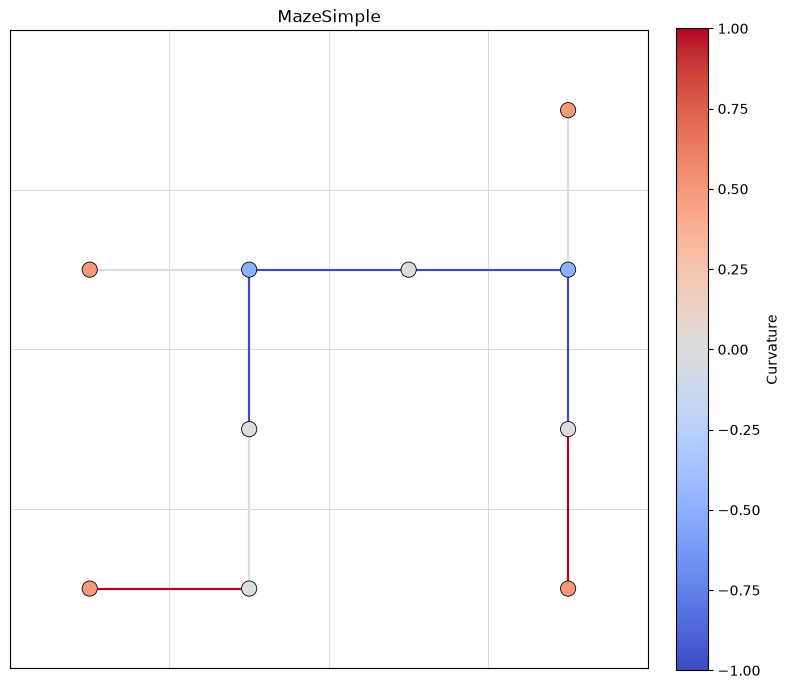

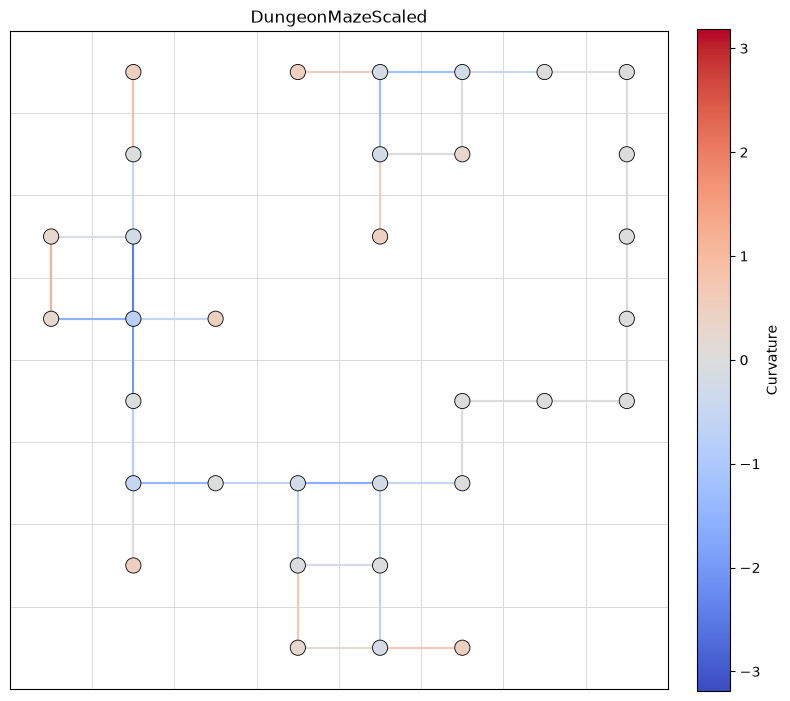

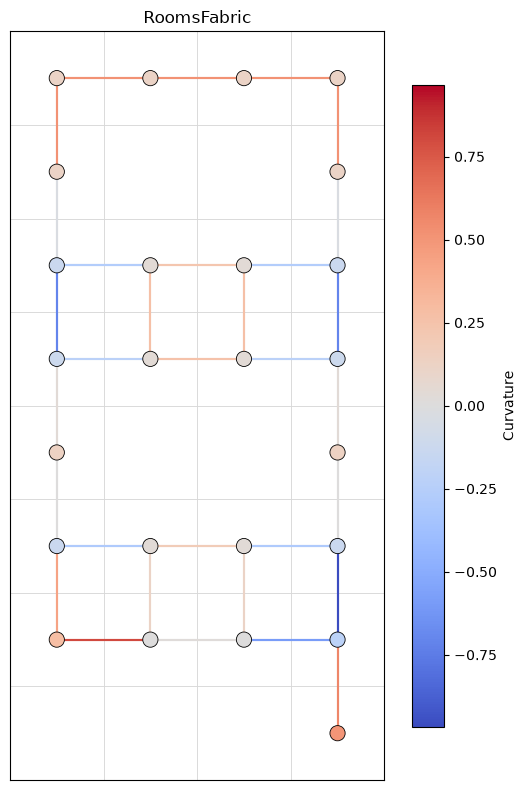

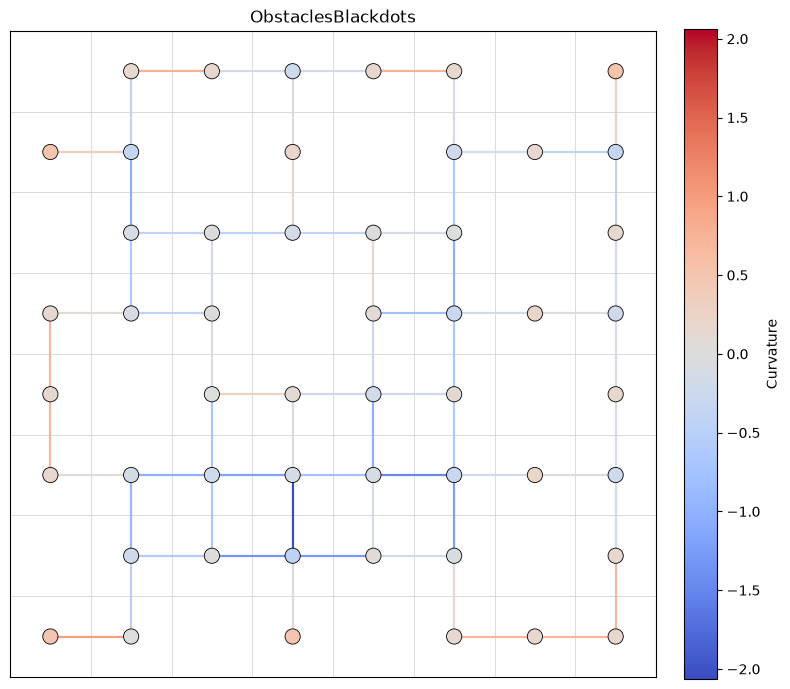

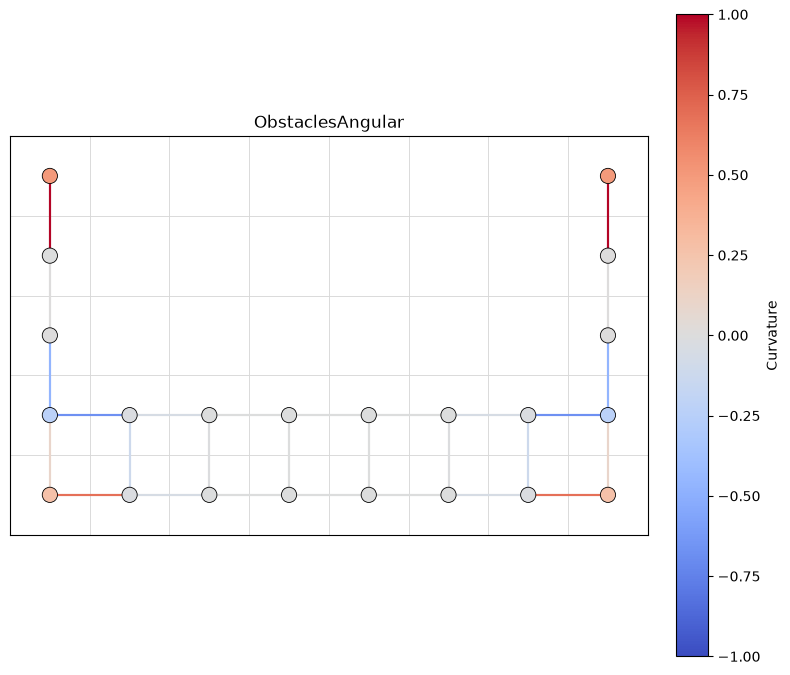

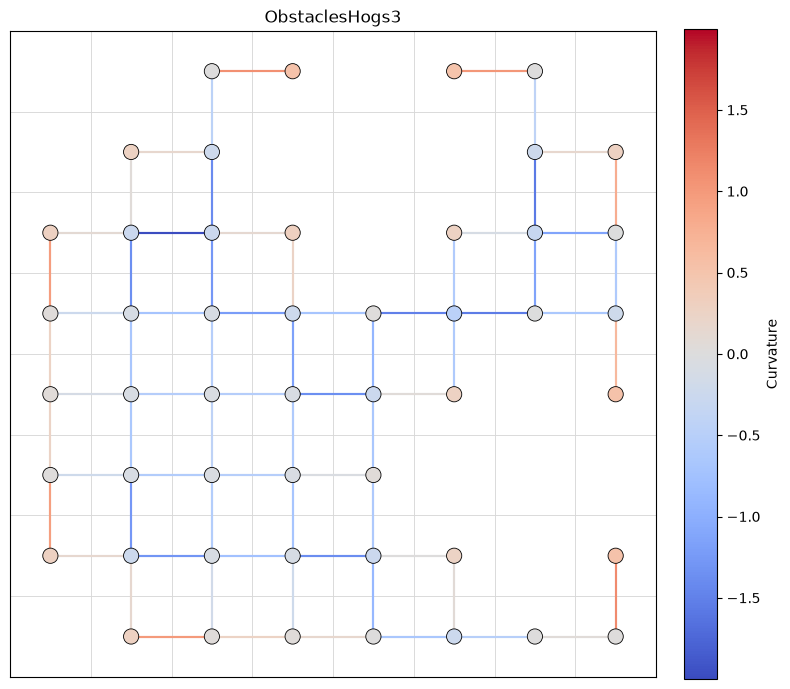

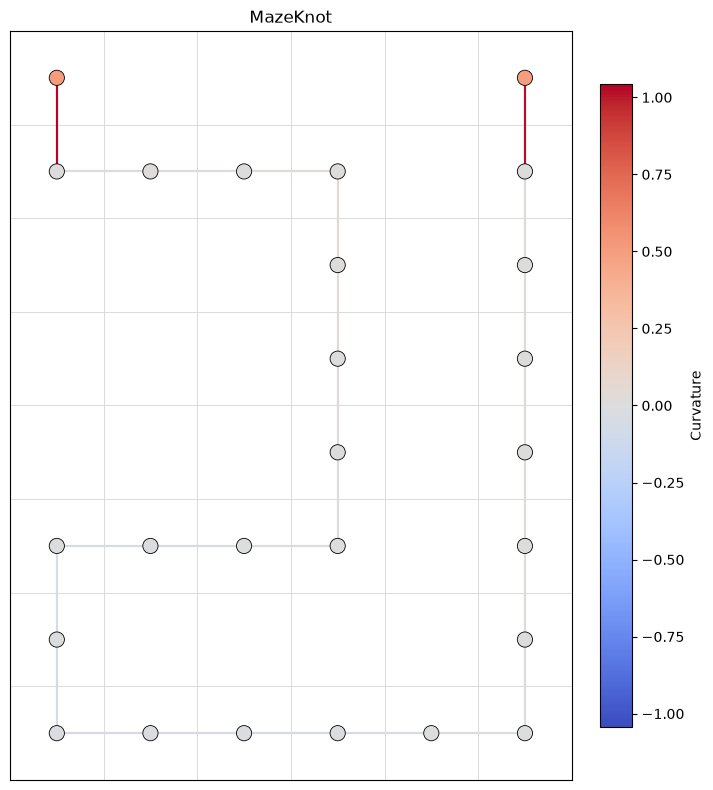

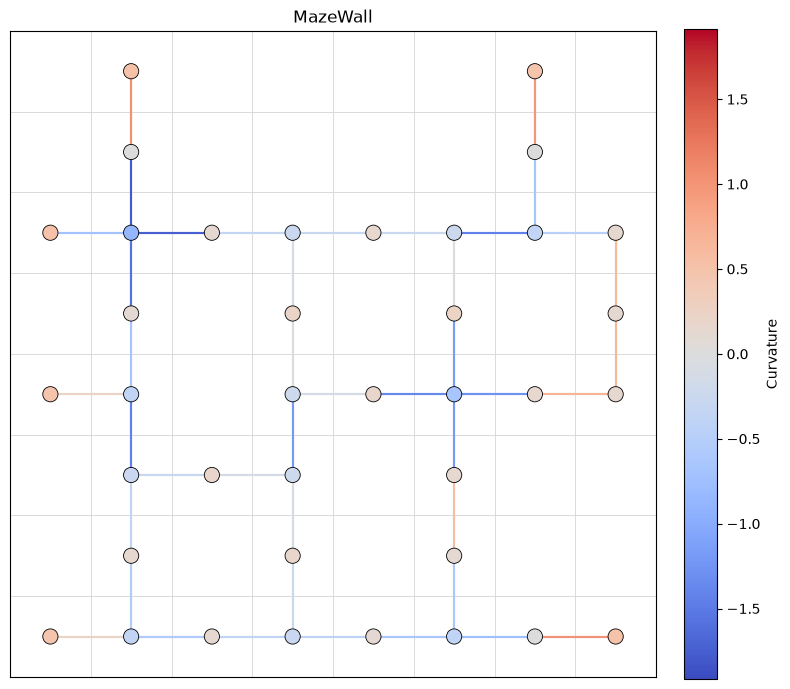

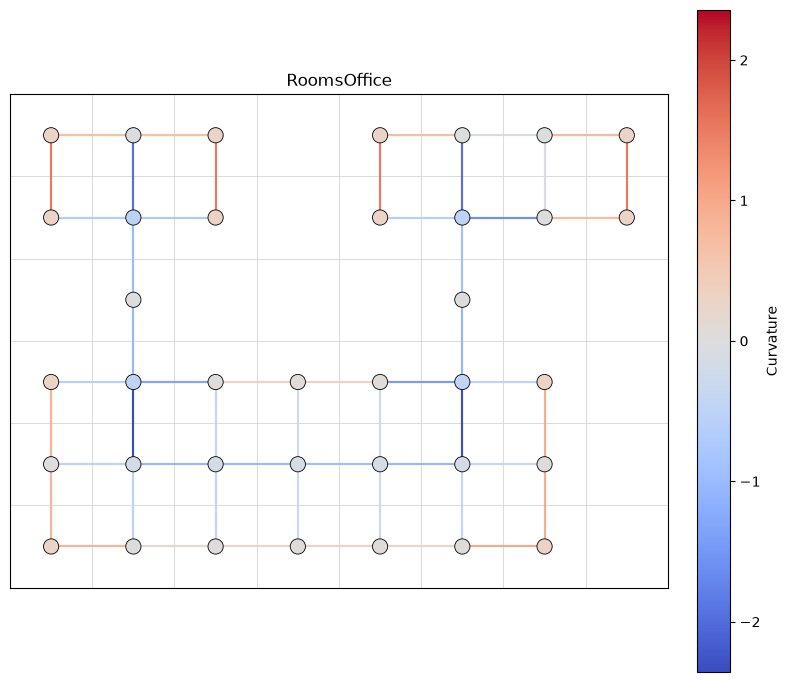

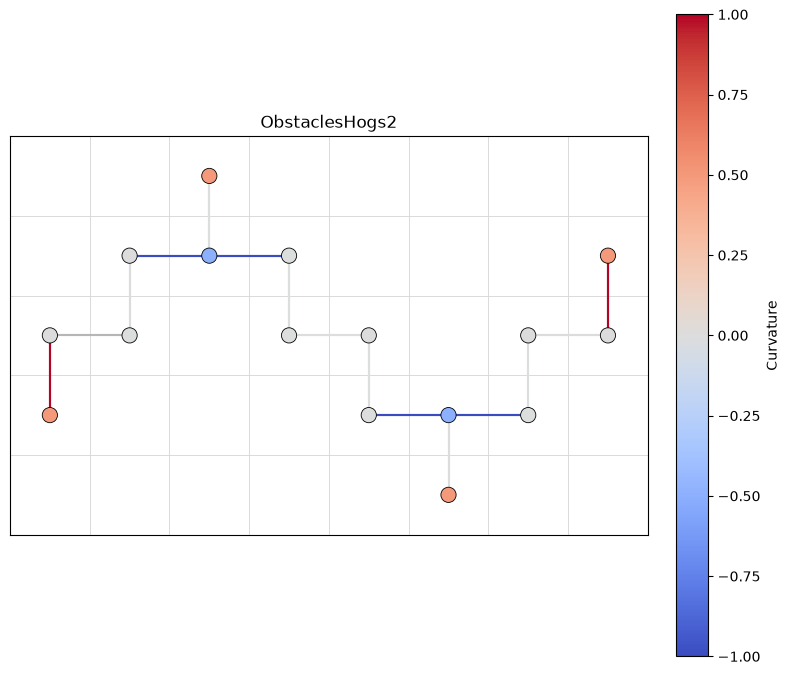

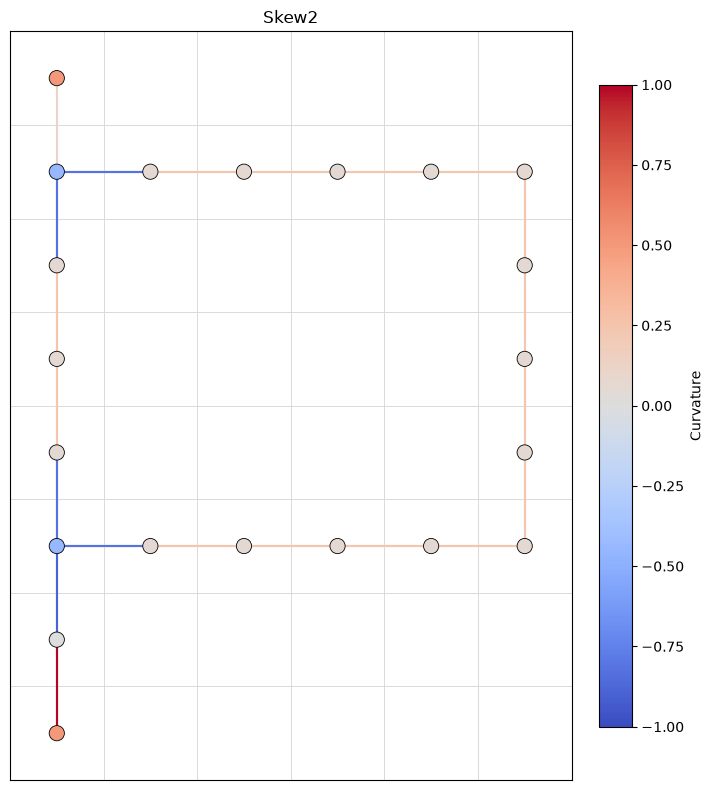

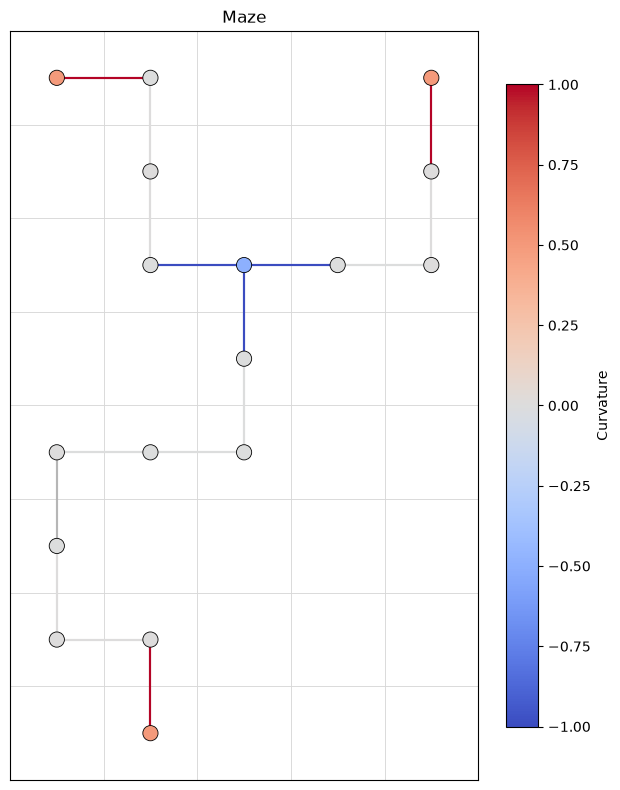

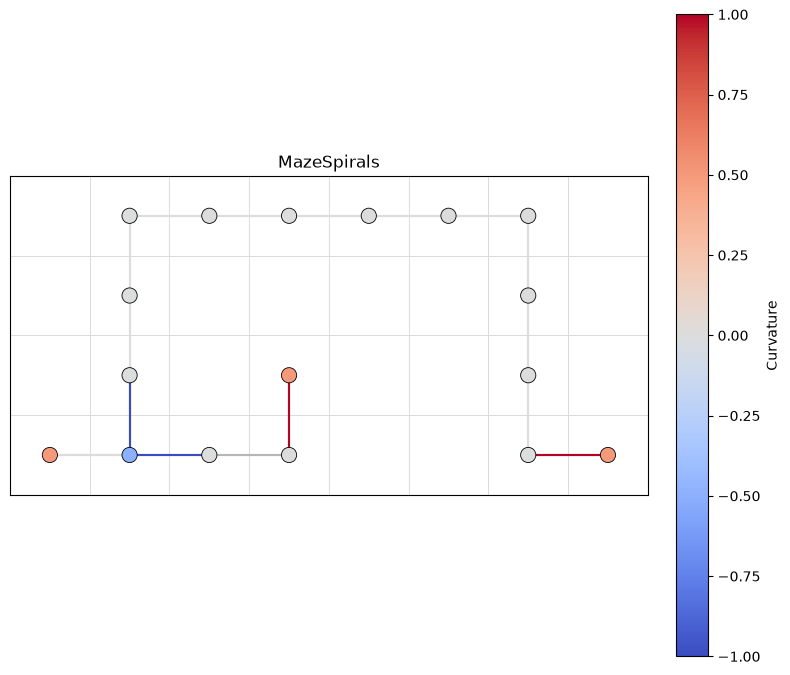

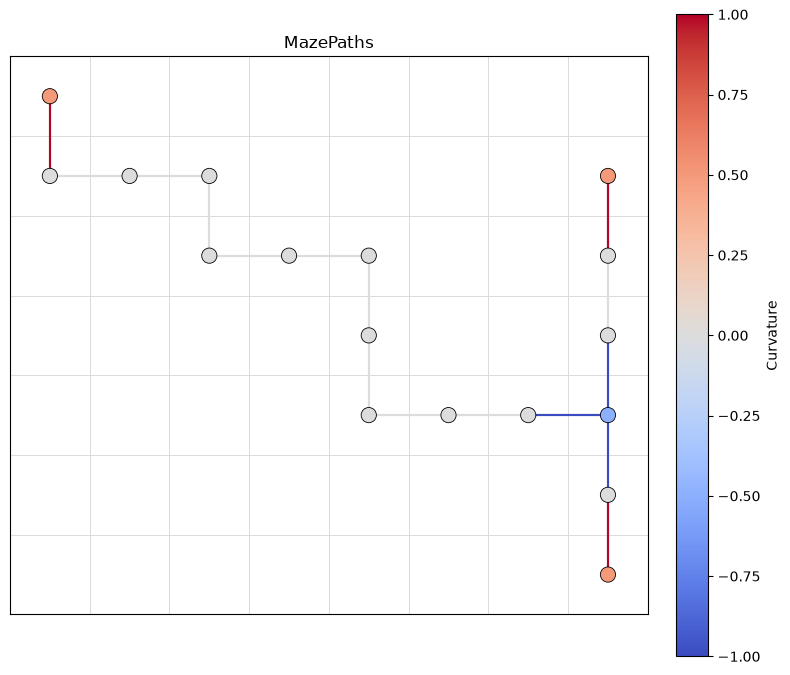

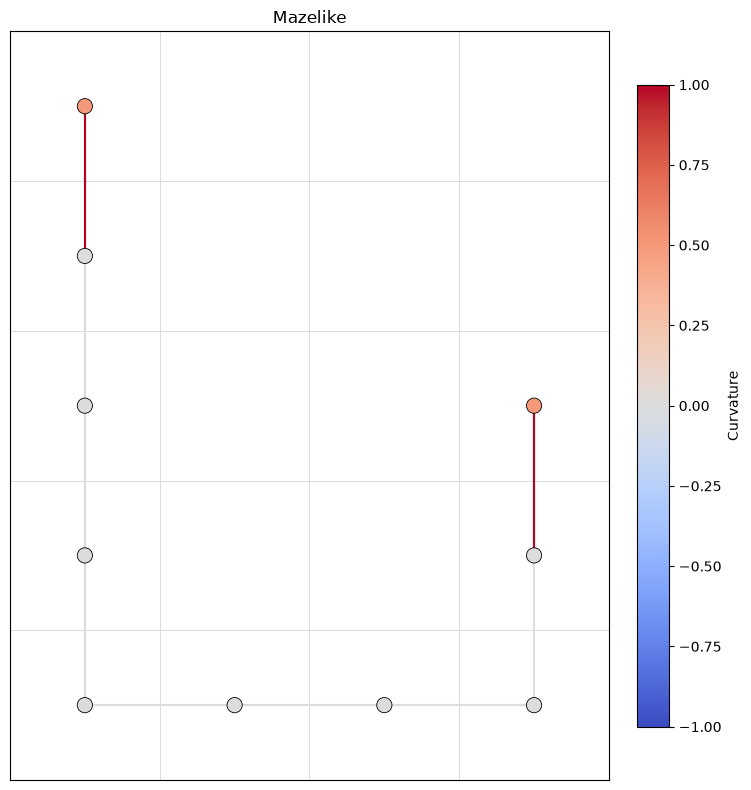

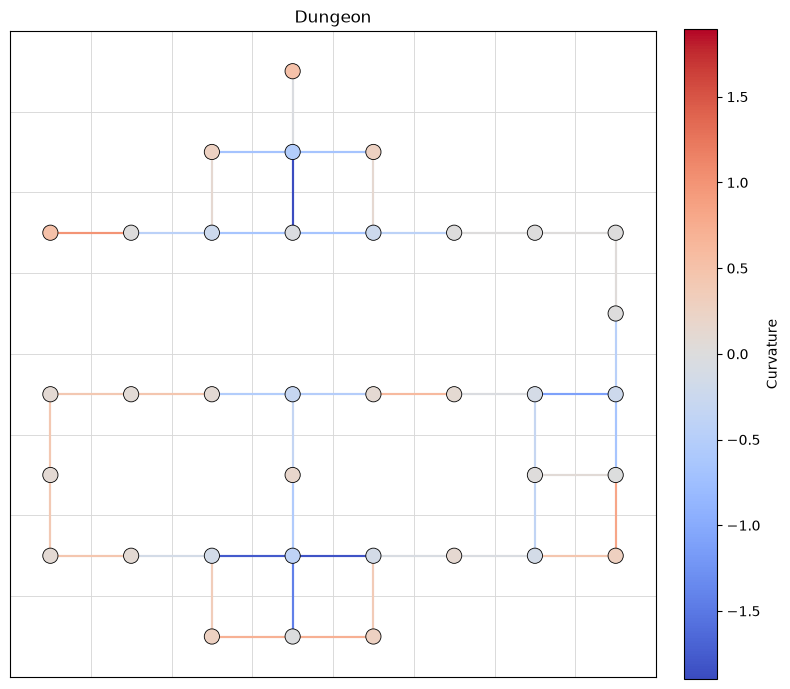

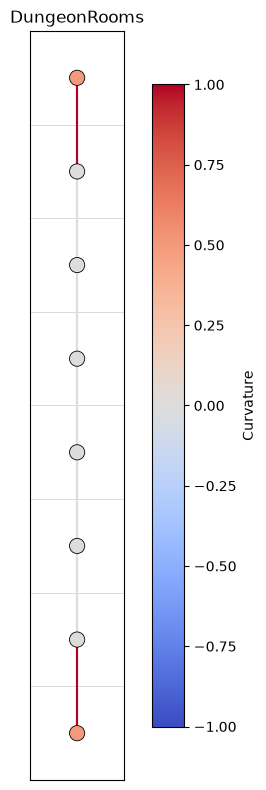

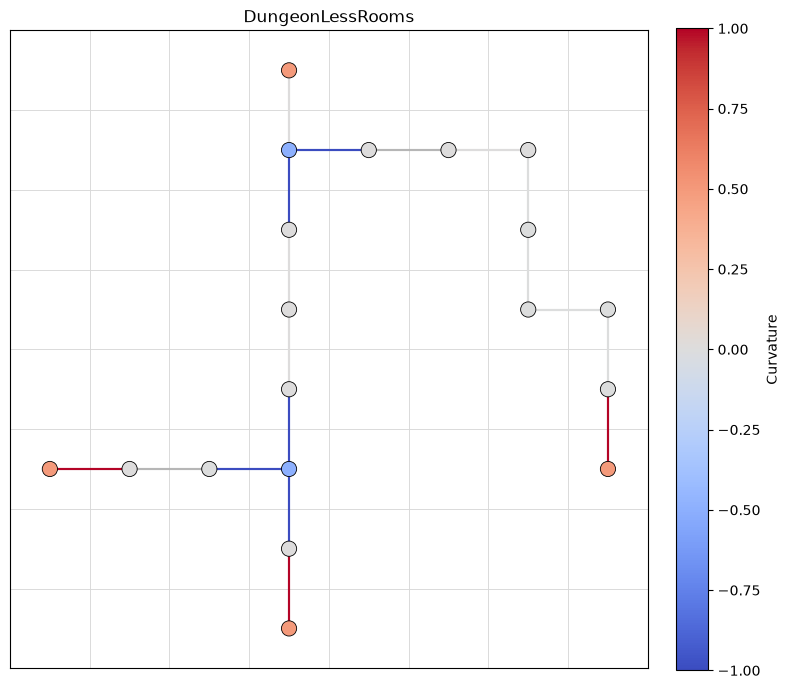

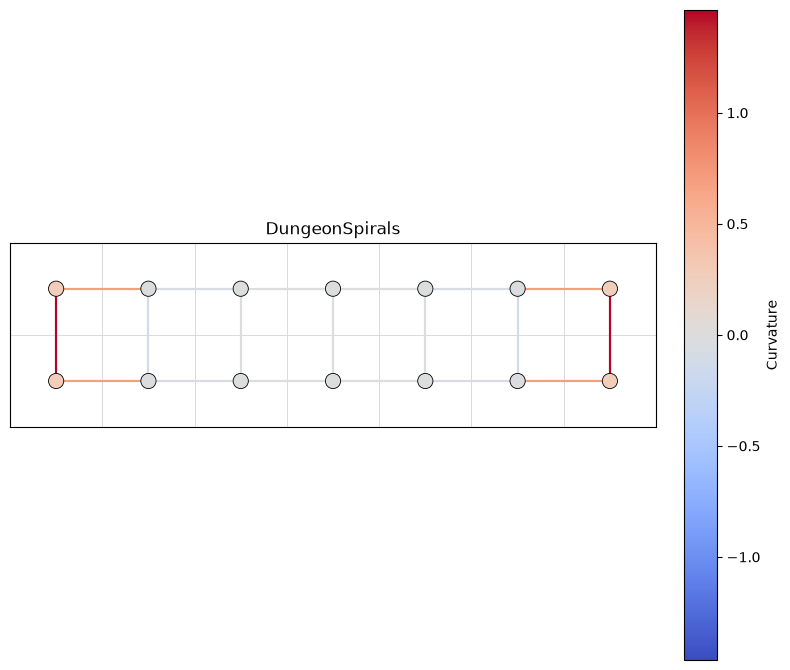

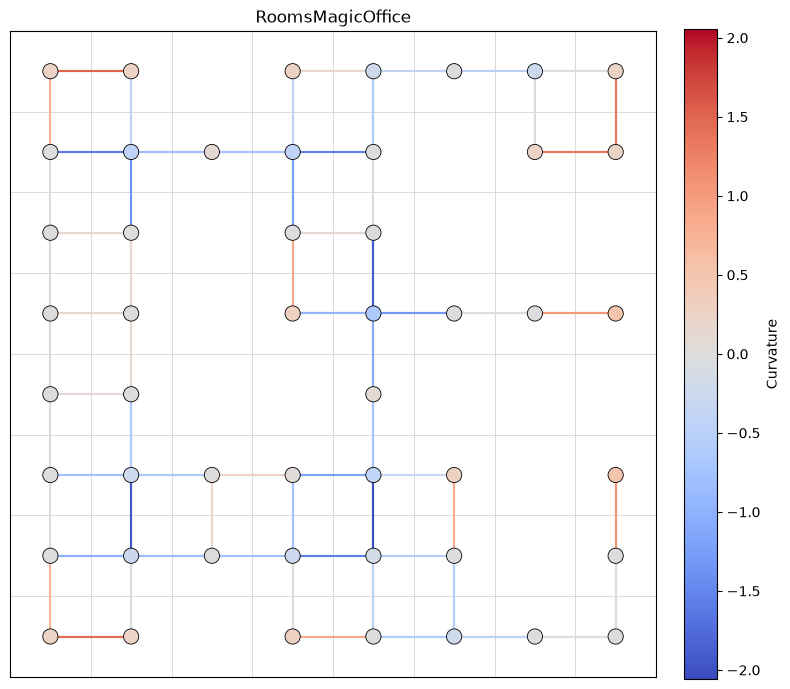

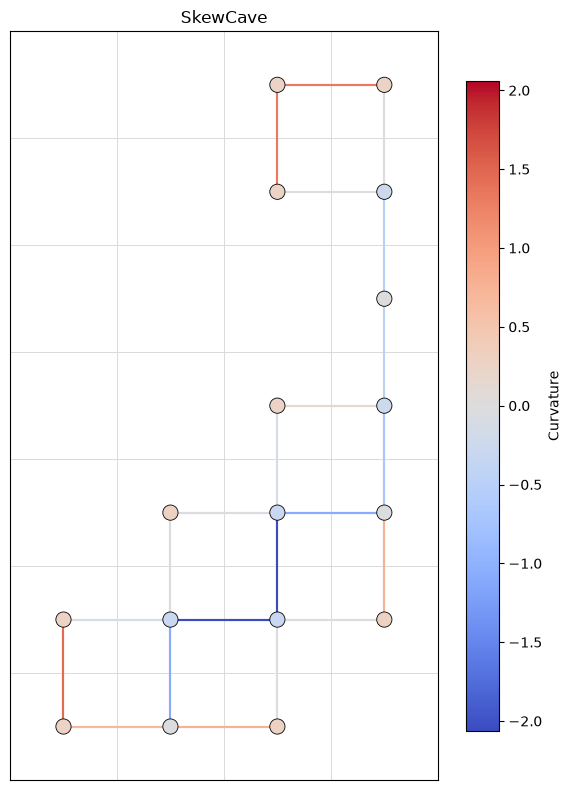

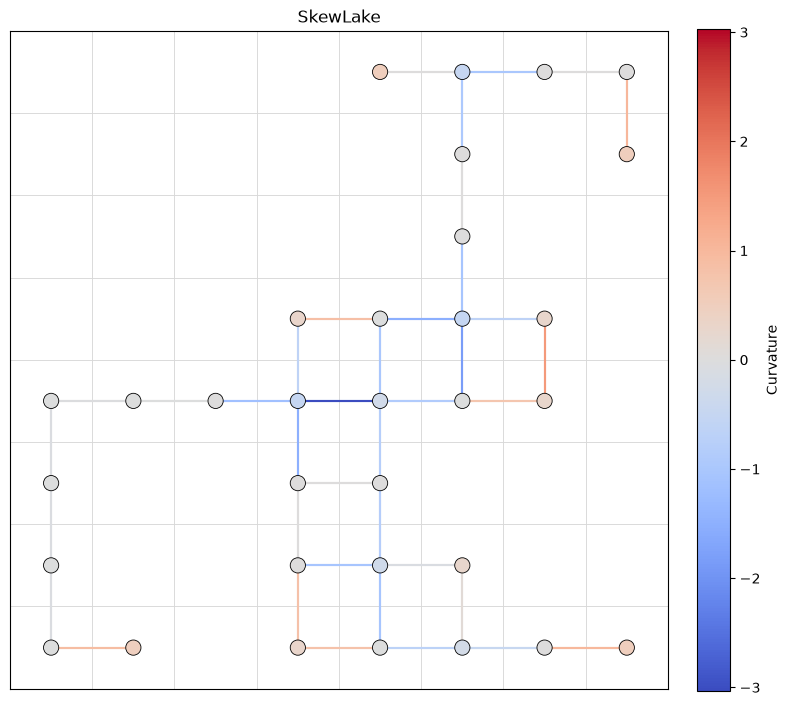

In [14]:
for env_string in env_list:
    setup_env(env_string,10,True)